# Phase 2: MRI Image Preprocessing Pipeline

Scientific rationale and execution notebook for MRI image preprocessing:
1. **Resizing**: Standardizing all MRI slices to `224x224` resolution for deep learning backbones.
2. **Channel Standardization**: Converting grayscale/single channel to 3-channel RGB.
3. **Contrast Limited Adaptive Histogram Equalization (CLAHE)**: Enhancing tissue boundary contrast without over-amplifying noise.
4. **Gaussian Denoising**: Removing acquisition noise while preserving high-frequency tumor boundary details.
5. **Normalization**: Scaling pixel intensity values to standard range.
6. **Data Pipeline Integration**: Building `tf.data` and `ImageDataGenerator` pipelines.


In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import Image, display

sys.path.append("C:/Research_Project/Brain_Tumor_Project")
from src.mri_preprocessing import (
    load_image, preprocess_pipeline, apply_clahe, apply_gaussian_blur
)


## 1. Preprocessing Summary Metadata

In [2]:
meta_df = pd.read_csv("C:/Research_Project/Brain_Tumor_Project/results/reports/MRI_Preprocessing_Metadata.csv")
print(f"Total Processed MRI Slices: {len(meta_df)}")
print(f"Classes: {meta_df['class'].unique().tolist()}")
meta_df.head()


Total Processed MRI Slices: 7200
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


,original_filename,class,original_path,processed_path,original_width,original_height,processed_width,processed_height,channels,split
0,Tr-gl_1.jpg,glioma,C:\Research_Project\Brain_Tumor_Multimodal_Dat...,C:\Research_Project\Brain_Tumor_Project\data\p...,512,512,224,224,3,Training
1,Tr-gl_10.jpg,glioma,C:\Research_Project\Brain_Tumor_Multimodal_Dat...,C:\Research_Project\Brain_Tumor_Project\data\p...,512,512,224,224,3,Training
2,Tr-gl_100.jpg,glioma,C:\Research_Project\Brain_Tumor_Multimodal_Dat...,C:\Research_Project\Brain_Tumor_Project\data\p...,512,512,224,224,3,Training
3,Tr-gl_1000.jpg,glioma,C:\Research_Project\Brain_Tumor_Multimodal_Dat...,C:\Research_Project\Brain_Tumor_Project\data\p...,512,512,224,224,3,Training
4,Tr-gl_1001.jpg,glioma,C:\Research_Project\Brain_Tumor_Multimodal_Dat...,C:\Research_Project\Brain_Tumor_Project\data\p...,512,512,224,224,3,Training


## 2. Visual Inspection of Pipeline Stages

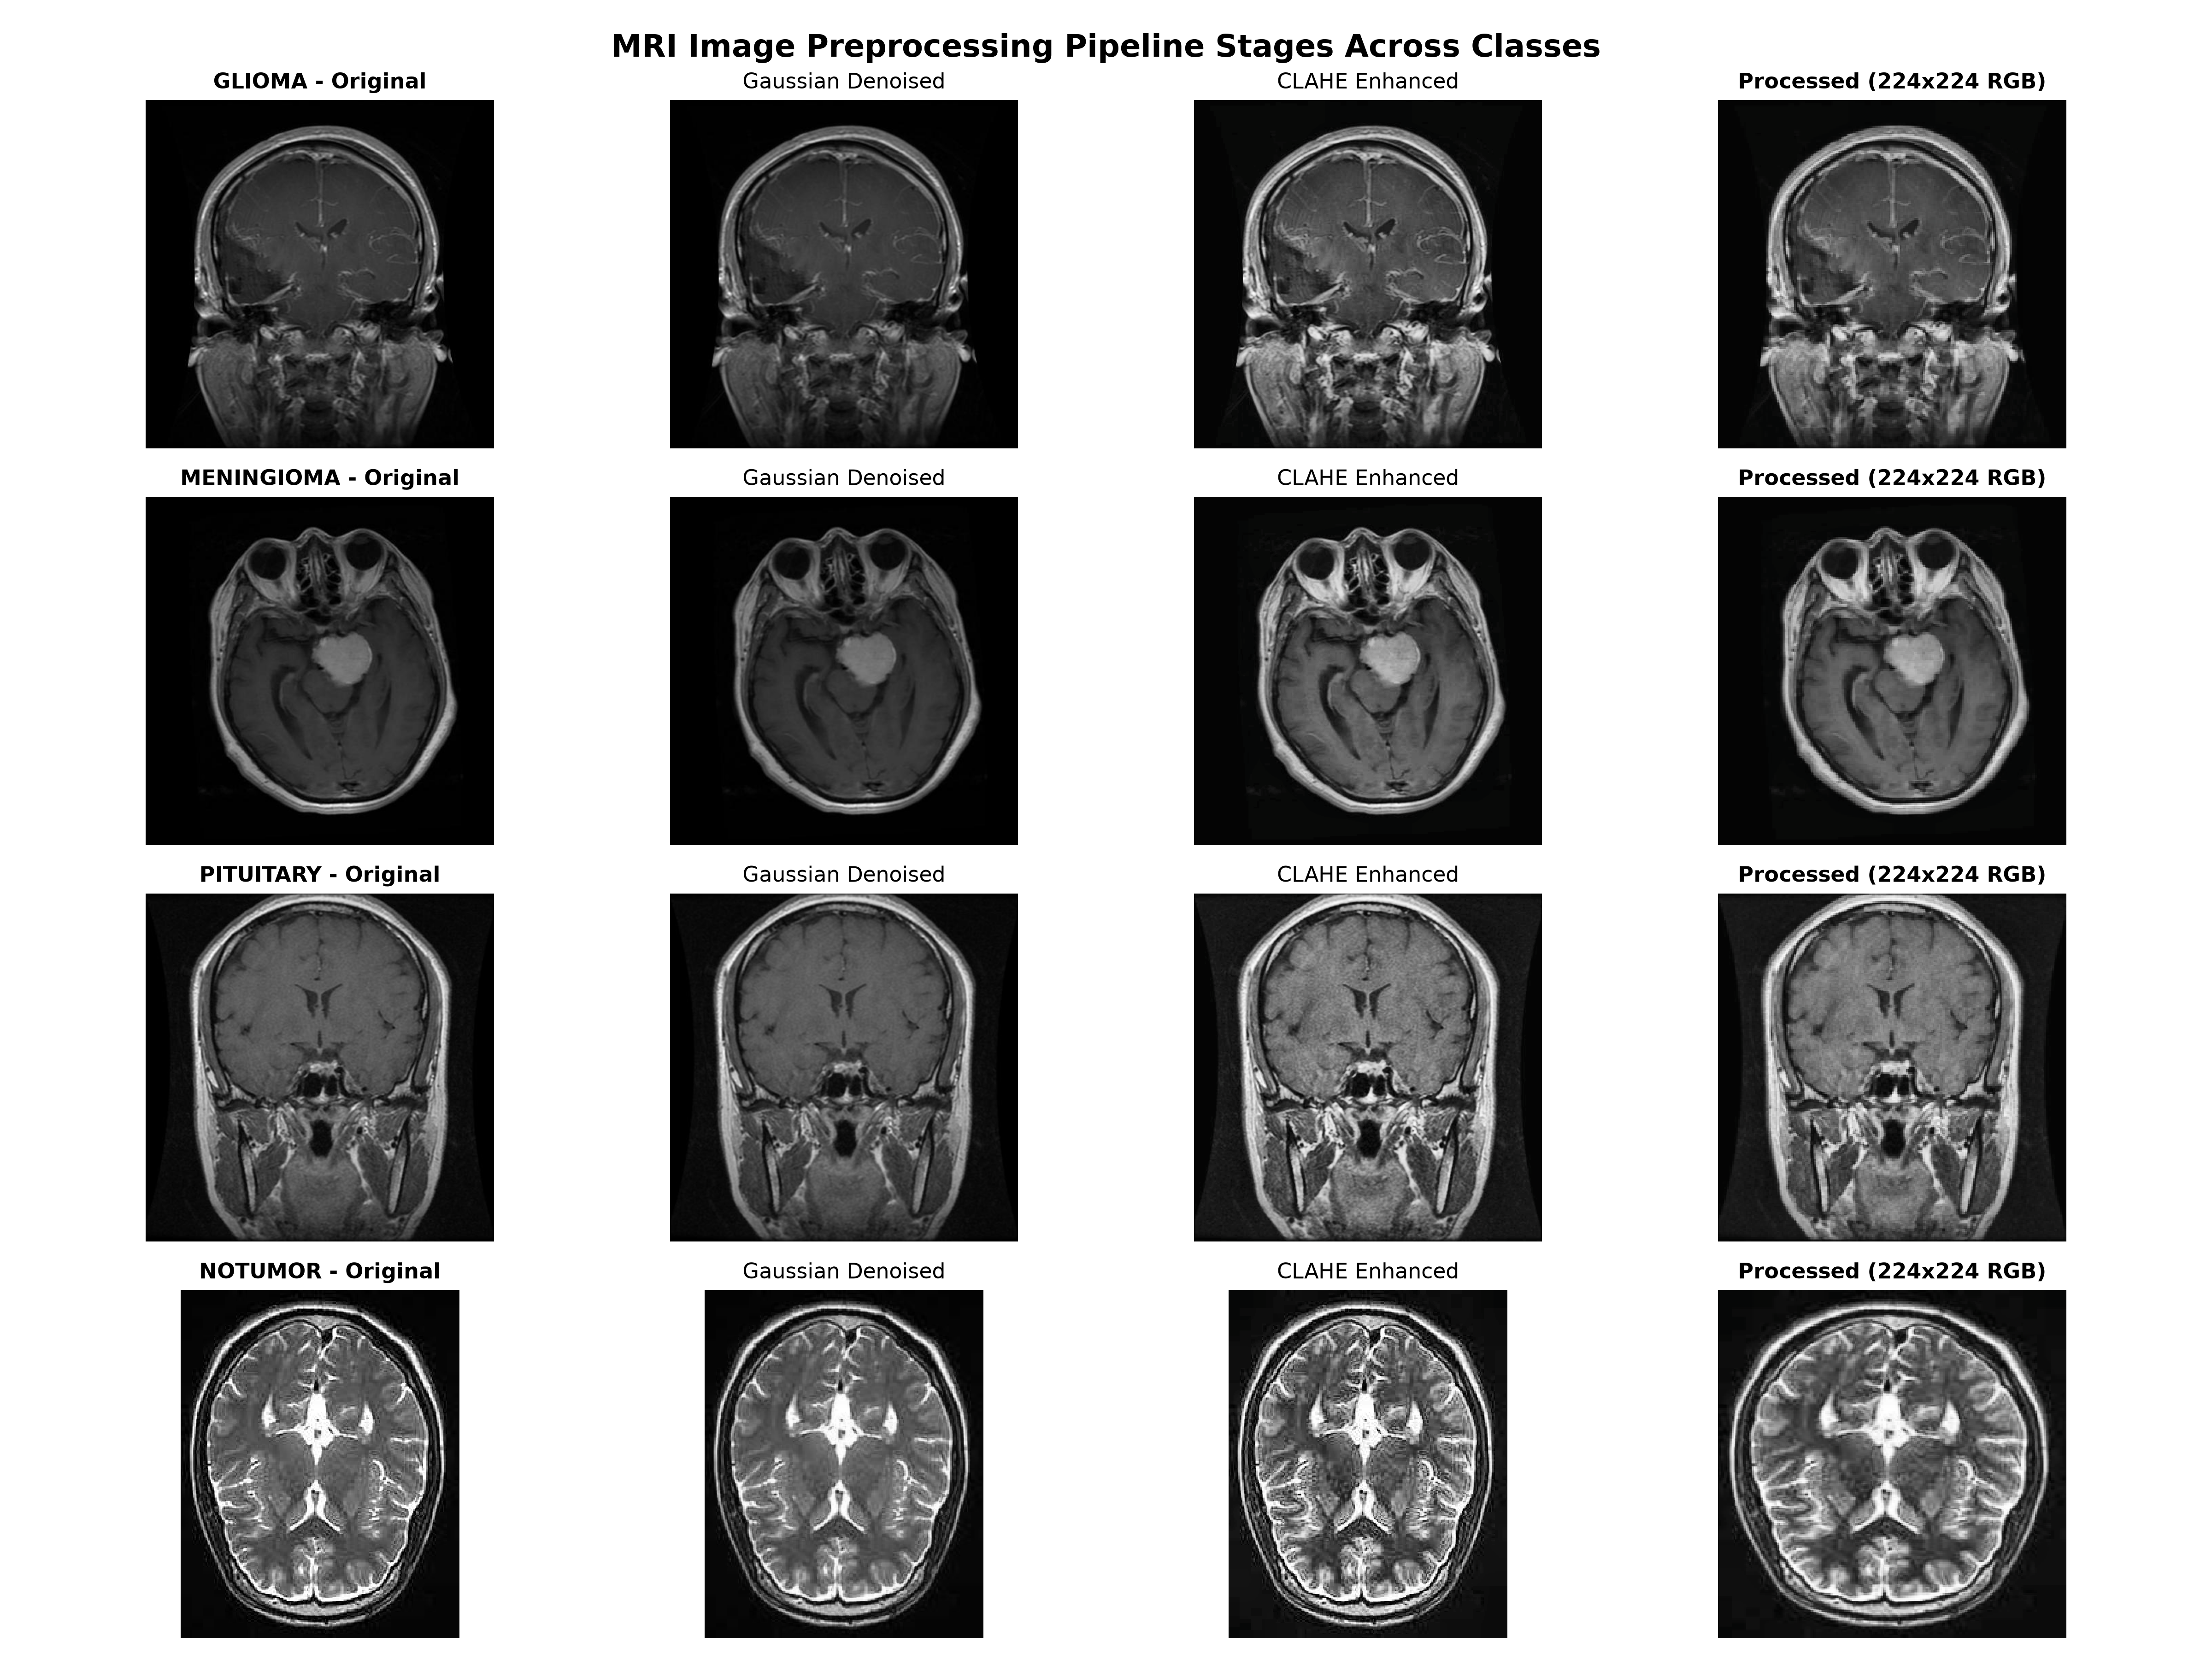

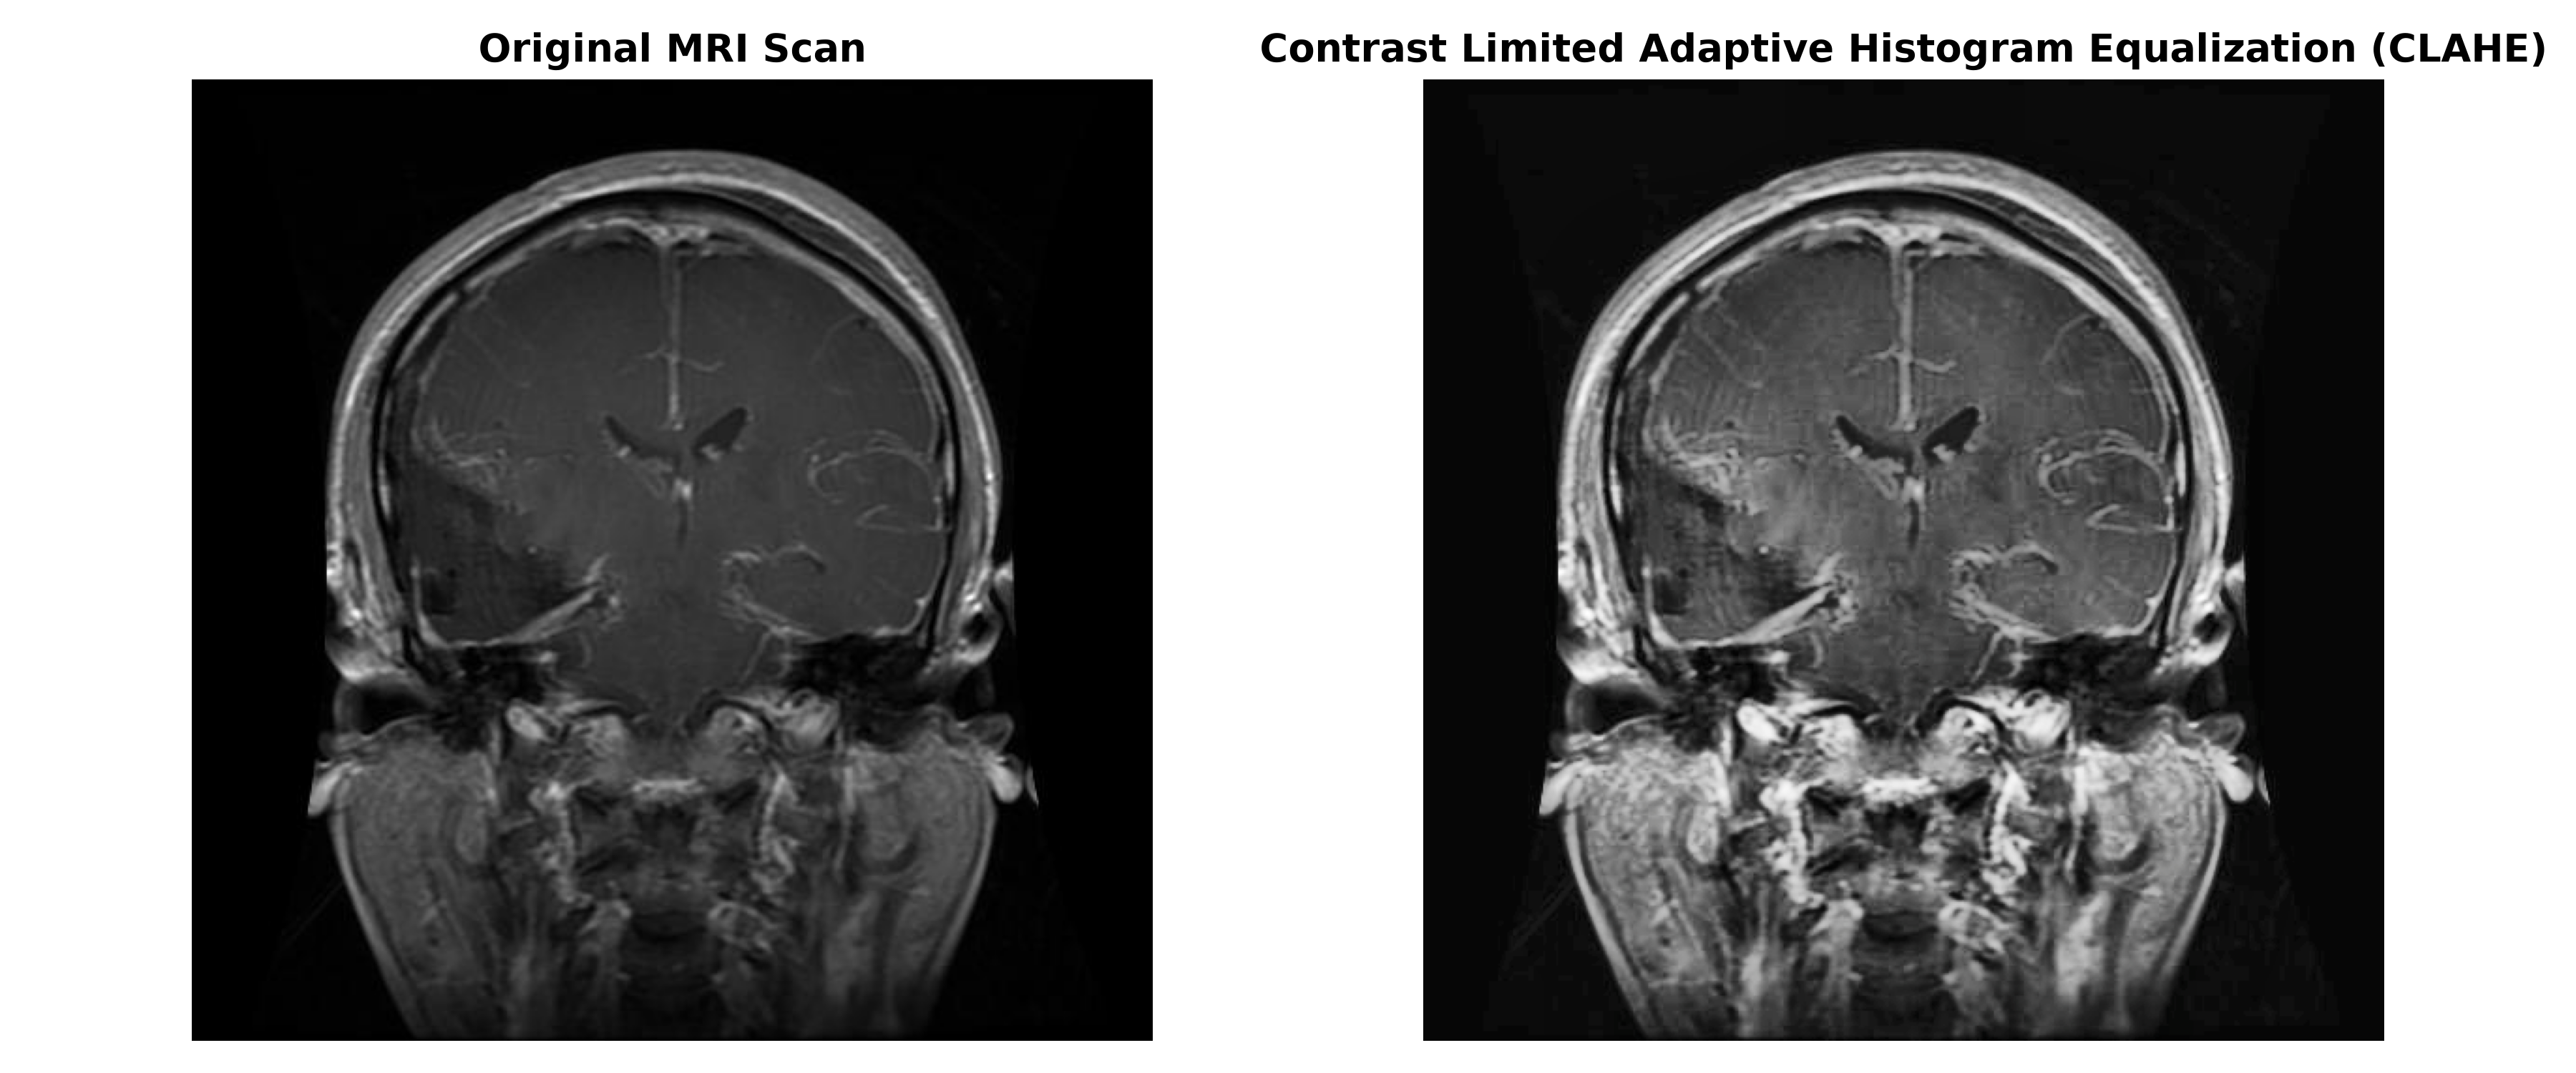

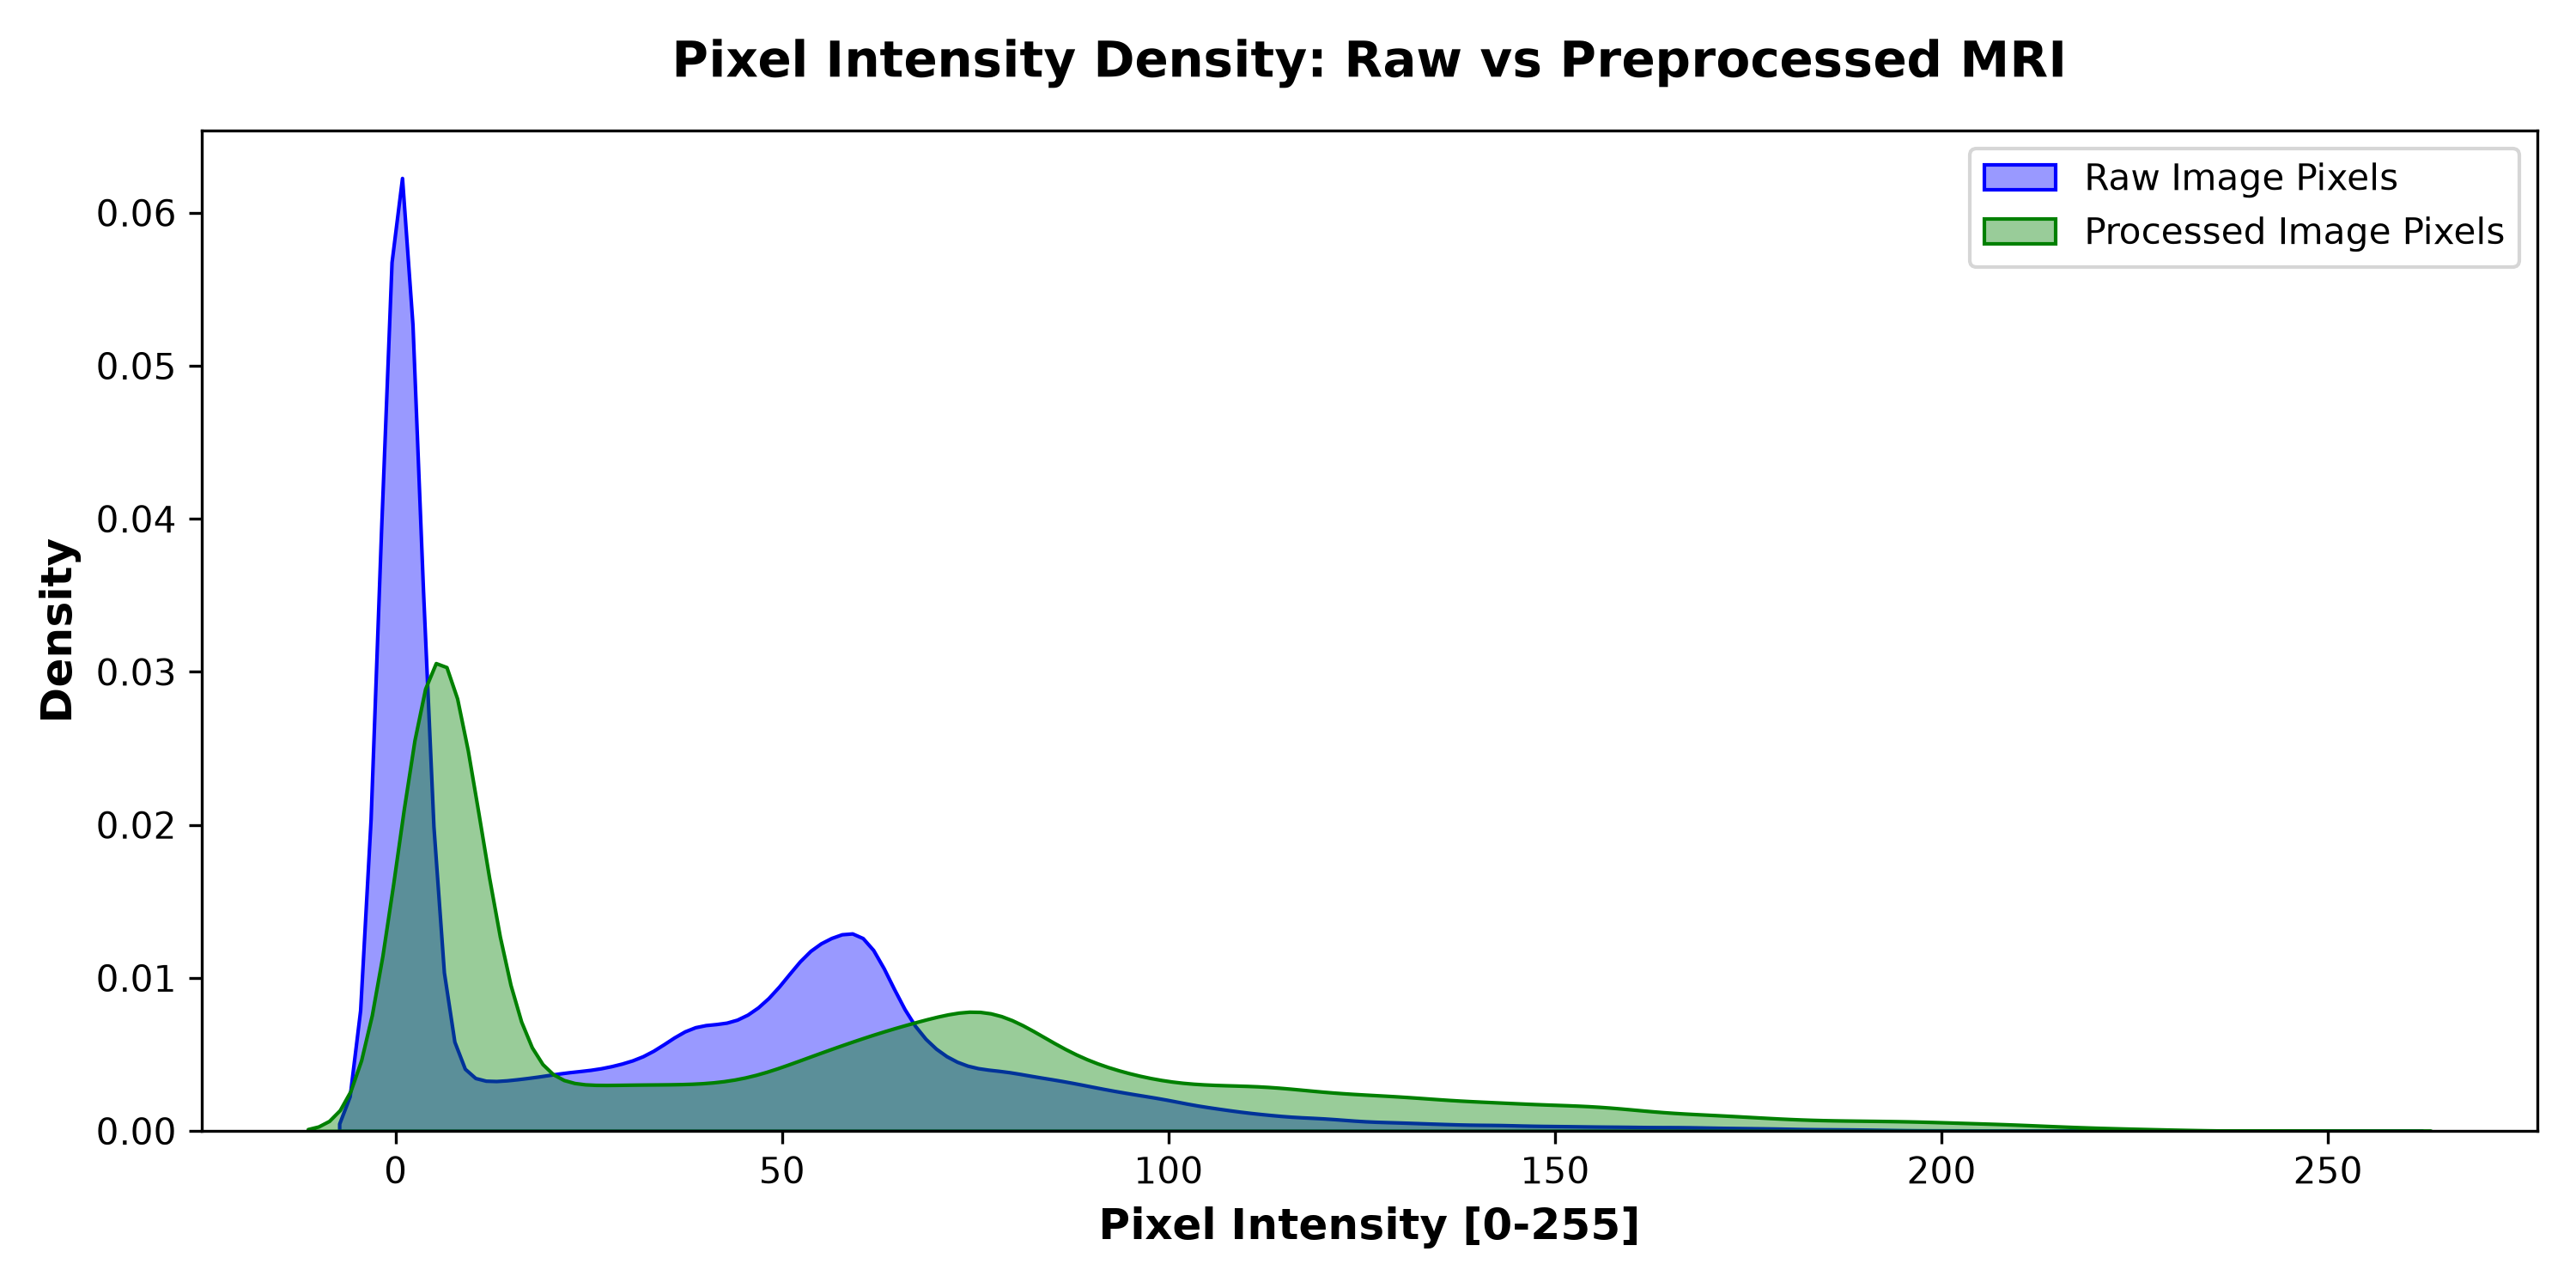

In [3]:
display(Image(filename="C:/Research_Project/Brain_Tumor_Project/results/figures/mri_before_after_comparison.png"))
display(Image(filename="C:/Research_Project/Brain_Tumor_Project/results/figures/mri_clahe_comparison.png"))
display(Image(filename="C:/Research_Project/Brain_Tumor_Project/results/figures/mri_pixel_distribution_comparison.png"))
